# Phase 2 walkthrough — probabilistic congestion and N-1 studies

Reads the outputs of `python -m src.run --phases 2` (re-runs it if missing). Sections: (1) how a Monte Carlo
scenario is built, (2) congestion probabilities with confidence intervals, (3) LMP distributions,
(4) rating sensitivity, (5) N-1 ranking. All numbers are from a synthetic, illustrative system.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from IPython.display import Image, display
from src.config import load_config, data_dir
cfg = load_config()
d = data_dir(cfg) / "phase2"
if not (d / "mc_lmp.parquet").exists():
    from src.run import phase2; phase2(cfg)
from src.run import load_result
from src.montecarlo import Scenarios
scen = Scenarios(pd.read_parquet(d / "mc_inputs.parquet"), pd.read_parquet(d / "mc_line_out.parquet"),
                 pd.read_parquet(d / "mc_gen_avail.parquet"))
res = load_result(d, "mc_")
summary = json.load(open("reports/phase2_summary.json"))
mc = summary["monte_carlo"]
print(f"{mc['n_scenarios']:,} scenarios, {mc['n_topologies']} topologies, {mc['n_lps']} LPs, "
      f"{mc['wall_seconds']:.1f}s wall on {mc['workers']} workers ({mc['sum_lp_seconds']:.1f}s summed LP time)")

20,000 scenarios, 33 topologies, 51 LPs, 24.5s wall on 4 workers (82.3s summed LP time)


## 1. What a scenario looks like
A base hour, perturbed load/renewables, sampled line outages and generator unit availability.

In [2]:
cols = ["base_timestamp", "hour", "month", "load_CAL", "load_SOUTH", "cf_wind_south", "cf_solar_south"]
ex = scen.inputs[cols].head(5).copy()
ex["lines_out"] = scen.out_lines.head(5).map(lambda t: ", ".join(t) or "—")
ex["MW_gen_on_outage"] = ((1 - scen.gen_avail.head(5)) * pd.Series({g: v["p_nom"] for g, v in cfg["generators"].items()})).sum(axis=1).round(0)
ex.round(2)

/tmp/ipykernel_9415/2804101000.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ex.round(2)


,base_timestamp,hour,month,load_CAL,load_SOUTH,cf_wind_south,cf_solar_south,lines_out,MW_gen_on_outage
scenario,,,,,,,,,
0,2026-07-05 00:00:00,0,7,2249.54,713.14,0.02,0.00,—,800.0
1,2025-09-18 21:00:00,21,9,2935.03,942.94,0.99,0.00,—,1075.0
2,2025-01-06 02:00:00,2,1,3160.14,1037.47,0.65,0.00,—,1325.0
3,2025-09-29 17:00:00,17,9,3209.67,1015.12,0.78,0.16,—,750.0
4,2025-04-09 11:00:00,11,4,3158.57,989.37,0.31,0.02,—,1575.0


In [3]:
scen.out_lines.map(lambda t: ", ".join(t) or "(all lines in)").value_counts().head(10).to_frame("scenarios")

,scenarios
(all lines in),18355
BC-CAL,376
EDM-NORTH-2,228
SOUTH-RD,212
CAL-EDM,206
EDM-NORTH-1,195
SOUTH-CAL,167
RD-EDM,102
CAL-RD,98
"SOUTH-CAL, BC-CAL",6


## 2. Congestion probability per line (95% Wilson CI)

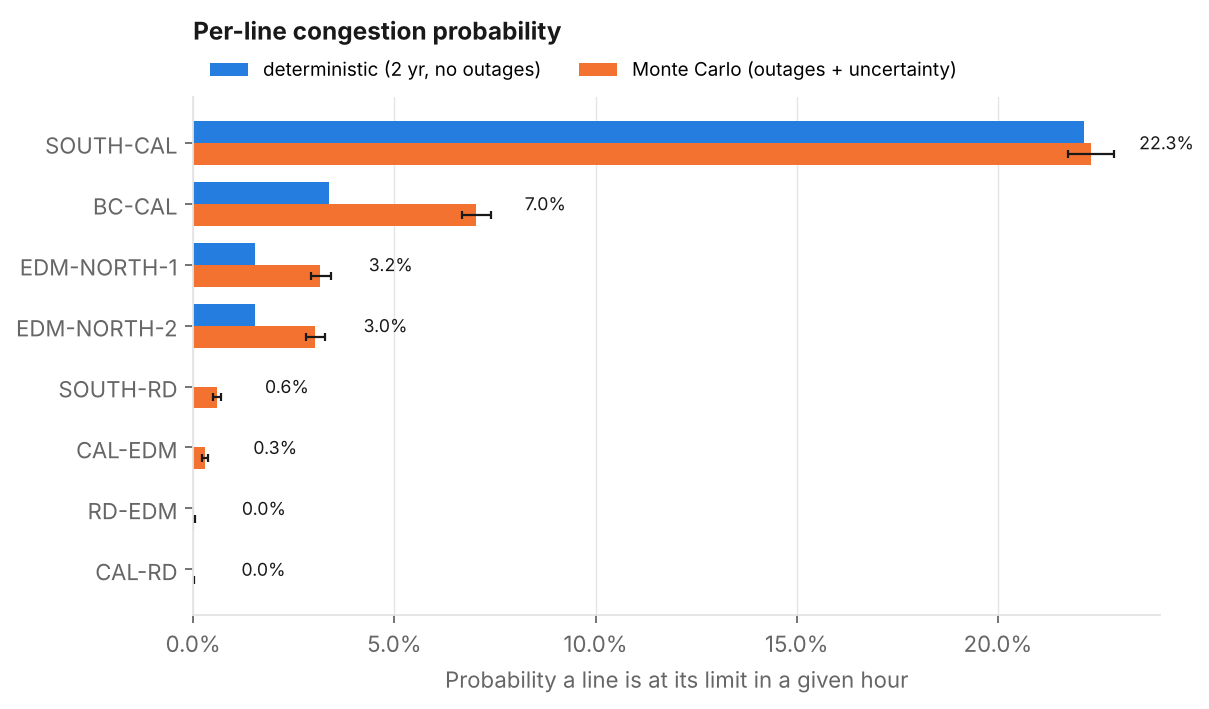

,deterministic_share,p_congested,ci95_low,ci95_high,expected_hours_per_year,p_congested_all_lines_in,p_congested_any_line_out,p_out_of_service
SOUTH-CAL,0.2214,0.2231,0.2174,0.2289,1954.356,0.2219,0.2365,0.0093
BC-CAL,0.0337,0.0704,0.0669,0.0740,616.704,0.0672,0.1064,0.0198
EDM-NORTH-1,0.0153,0.0316,0.0293,0.0342,277.254,0.0200,0.1611,0.0109
EDM-NORTH-2,0.0153,0.0304,0.0281,0.0328,265.866,0.0200,0.1453,0.0122
SOUTH-RD,0.0000,0.0058,0.0049,0.0070,51.246,0.0001,0.0705,0.0115
CAL-EDM,0.0000,0.0030,0.0023,0.0038,25.842,0.0000,0.0359,0.0108
RD-EDM,0.0000,0.0001,0.0000,0.0004,0.876,0.0000,0.0012,0.0055
CAL-RD,0.0000,0.0000,0.0000,0.0002,0.000,0.0000,0.0000,0.0054


In [4]:
display(Image("reports/figures/mc_congestion_probability.png", width=720))
pd.read_csv("reports/tables/mc_line_congestion.csv", index_col=0).round(4)

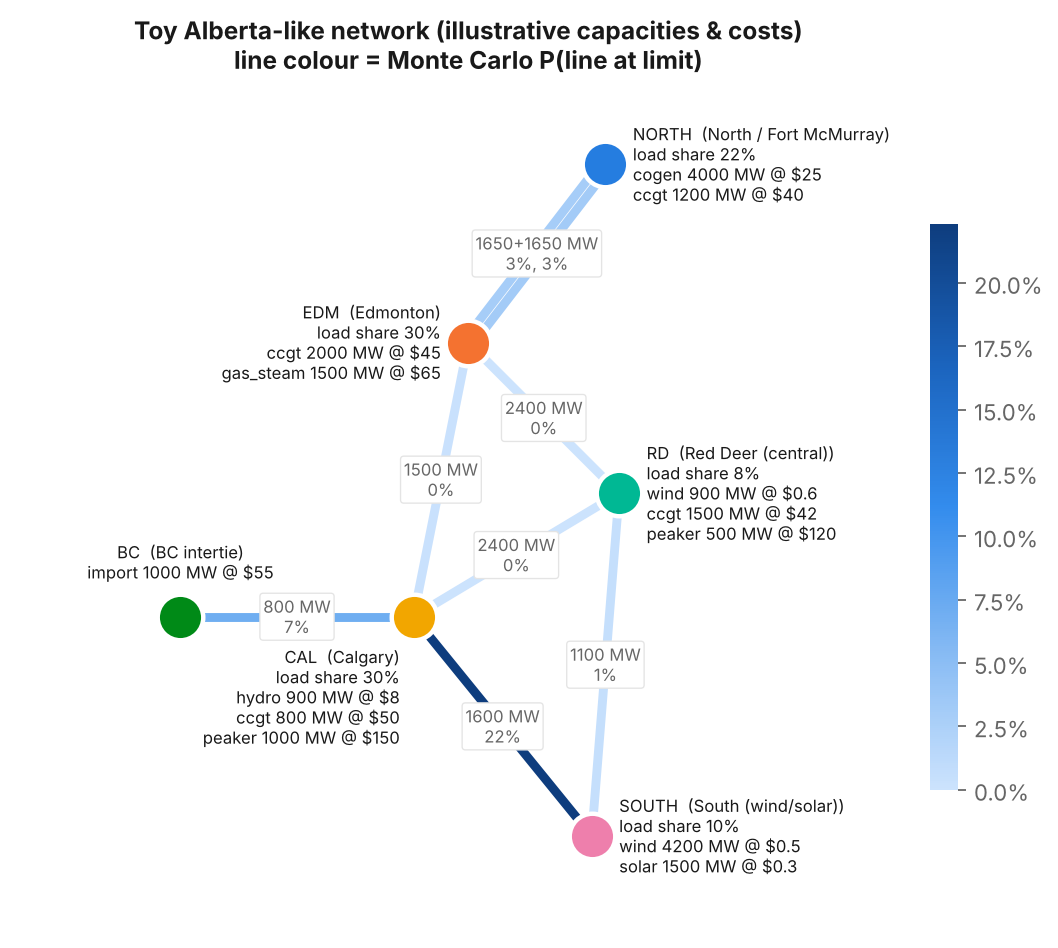

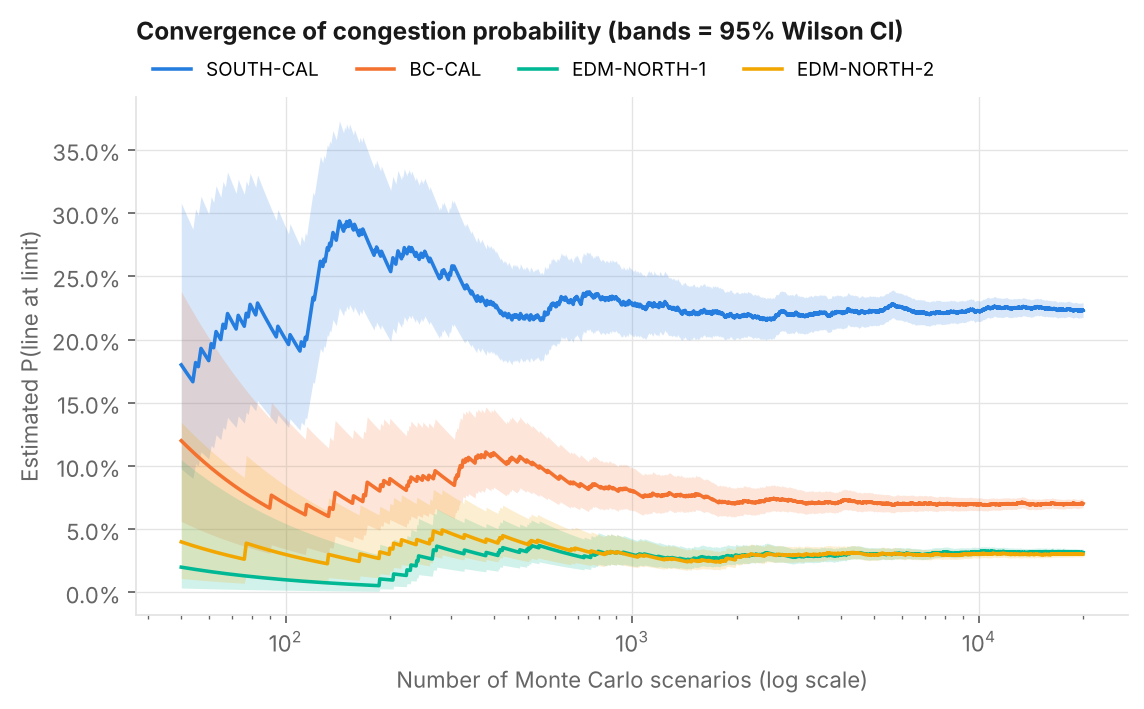

In [5]:
display(Image("reports/figures/network_mc_congestion.png", width=620))
display(Image("reports/figures/mc_convergence.png", width=720))

## 3. LMP distributions

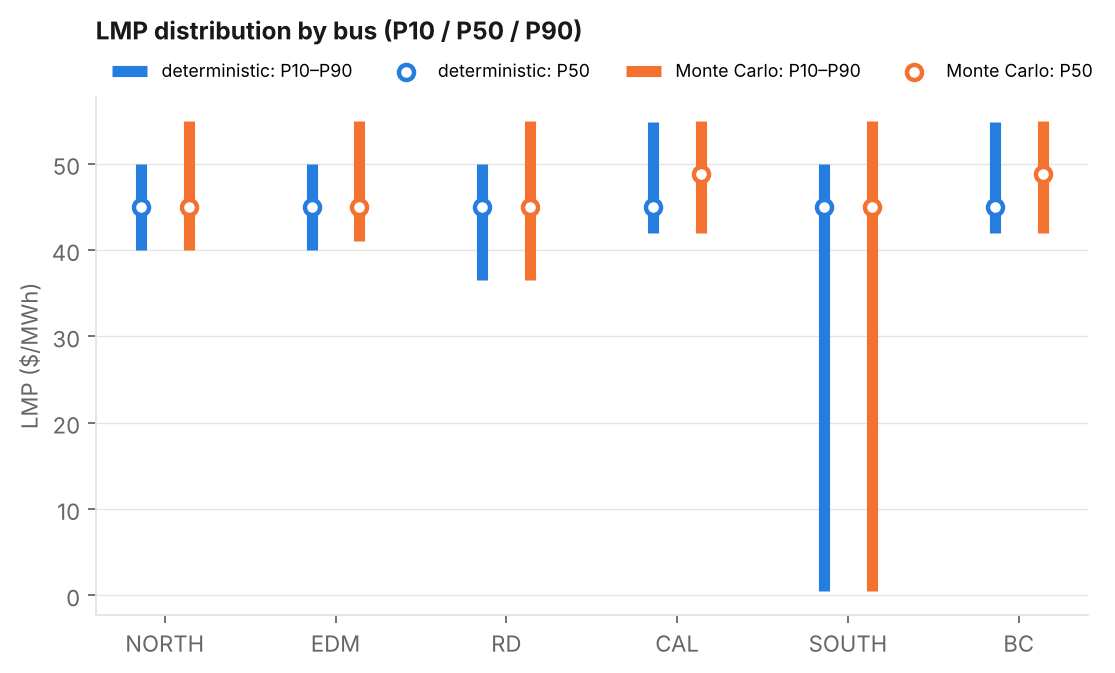

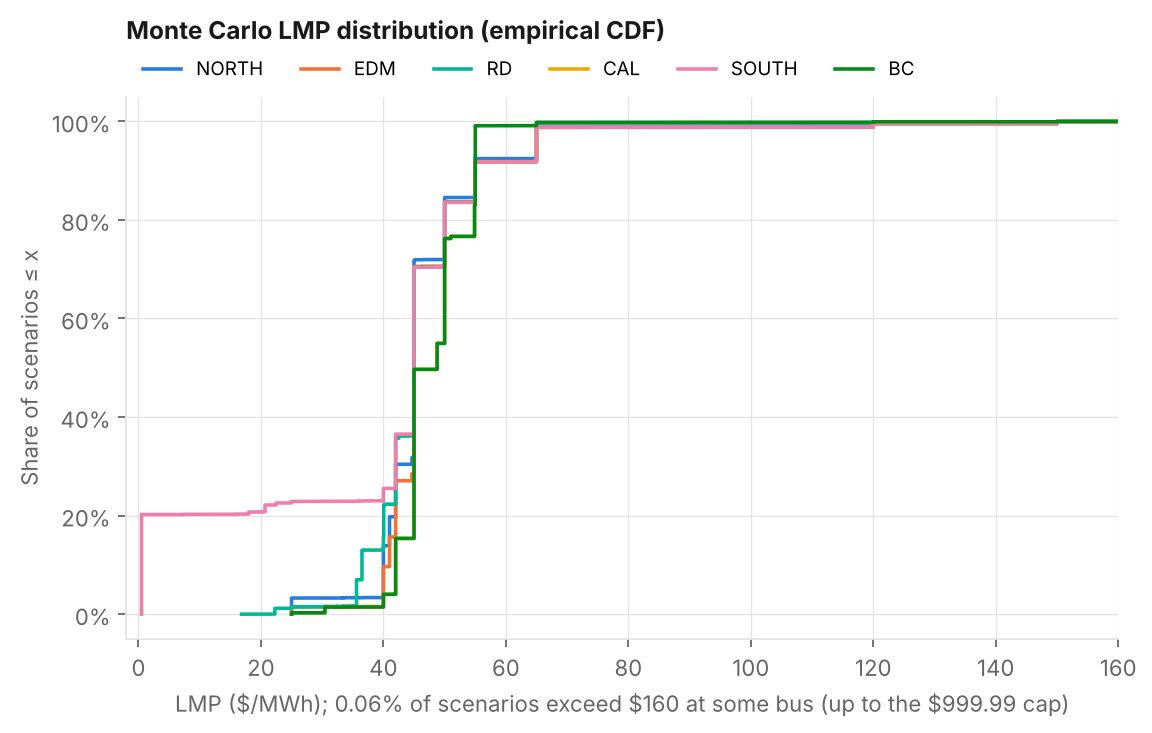

,P10,P50,P90,P99,mean,p_lmp_ge_100,p_lmp_at_cap,share_undefined_islanded
NORTH,40.0,45.000,55.0,65.0,47.016,0.009,0.000,0.00
EDM,41.0,45.000,55.0,120.0,47.851,0.011,0.000,0.00
RD,36.5,45.000,55.0,120.0,46.973,0.012,0.000,0.00
CAL,42.0,48.778,55.0,120.0,49.853,0.012,0.000,0.00
SOUTH,0.5,45.000,55.0,120.0,39.299,0.012,0.001,0.00
BC,42.0,48.778,55.0,55.0,48.309,0.002,0.000,0.02


In [6]:
display(Image("reports/figures/mc_lmp_intervals.png", width=720))
display(Image("reports/figures/mc_lmp_ecdf.png", width=720))
pd.read_csv("reports/tables/mc_lmp_quantiles.csv", index_col=0).round(3)

## 4. Rating sensitivity (common random numbers)

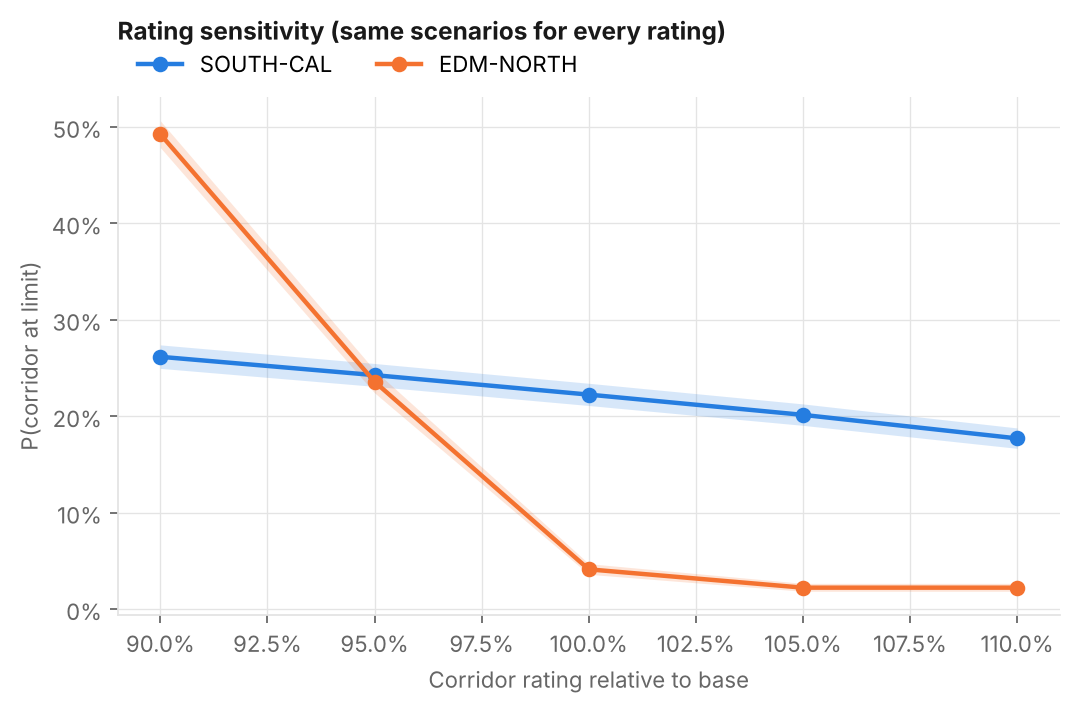

,corridor,rating_scale,rating_mw,p_corridor_congested,ci95_low,ci95_high,p_any_internal_congested,expected_congestion_rent_musd_per_year,expected_production_cost_musd_per_year
0,SOUTH-CAL,0.90,1440.0,0.262,0.250,0.274,0.302,262.515,2217.780
1,SOUTH-CAL,0.95,1520.0,0.243,0.231,0.255,0.283,254.602,2205.130
2,SOUTH-CAL,1.00,1600.0,0.222,0.211,0.234,0.264,242.300,2193.618
3,SOUTH-CAL,1.05,1680.0,0.201,0.191,0.213,0.244,229.661,2183.338
4,SOUTH-CAL,1.10,1760.0,0.177,0.167,0.188,0.222,210.326,2174.258
5,EDM-NORTH,0.90,2970.0,0.492,0.479,0.506,0.639,328.490,2198.653
6,EDM-NORTH,0.95,3135.0,0.236,0.224,0.248,0.435,273.195,2194.844
7,EDM-NORTH,1.00,3300.0,0.041,0.036,0.047,0.264,242.300,2193.618
8,EDM-NORTH,1.05,3465.0,0.022,0.018,0.027,0.246,239.786,2193.120
9,EDM-NORTH,1.10,3630.0,0.022,0.018,0.027,0.246,238.509,2192.698


In [7]:
display(Image("reports/figures/rating_sensitivity.png", width=680))
pd.read_csv("reports/tables/rating_sensitivity.csv").round(3)

## 5. N-1 contingency ranking
Security screen with pre-contingency dispatch (PTDF) + economic re-dispatch without the line.

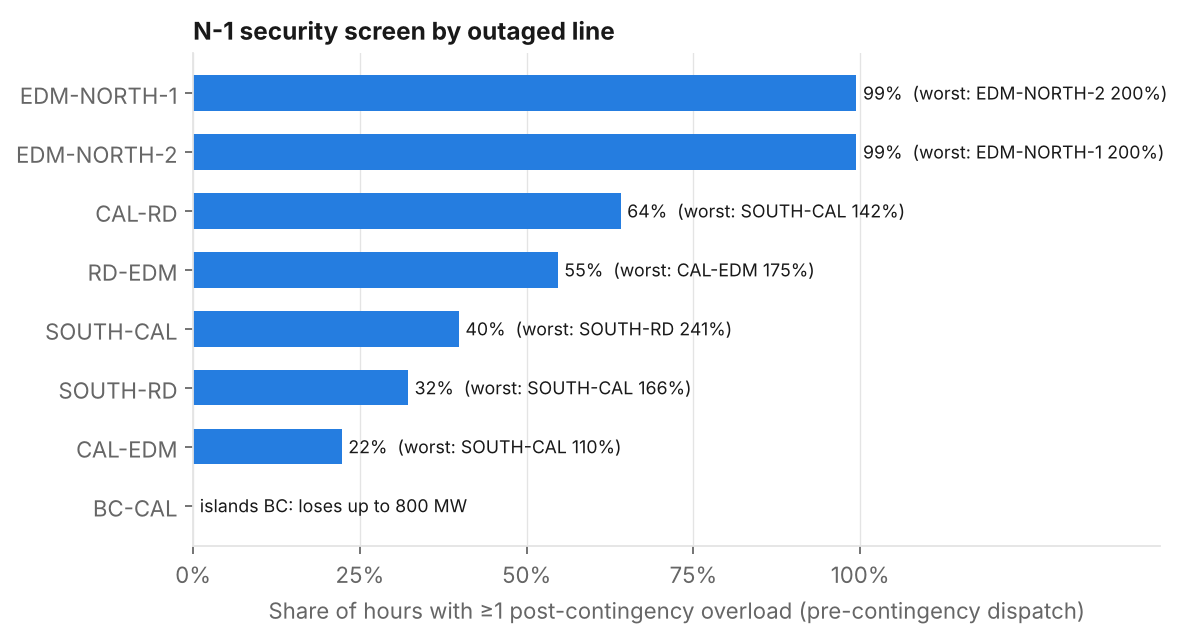

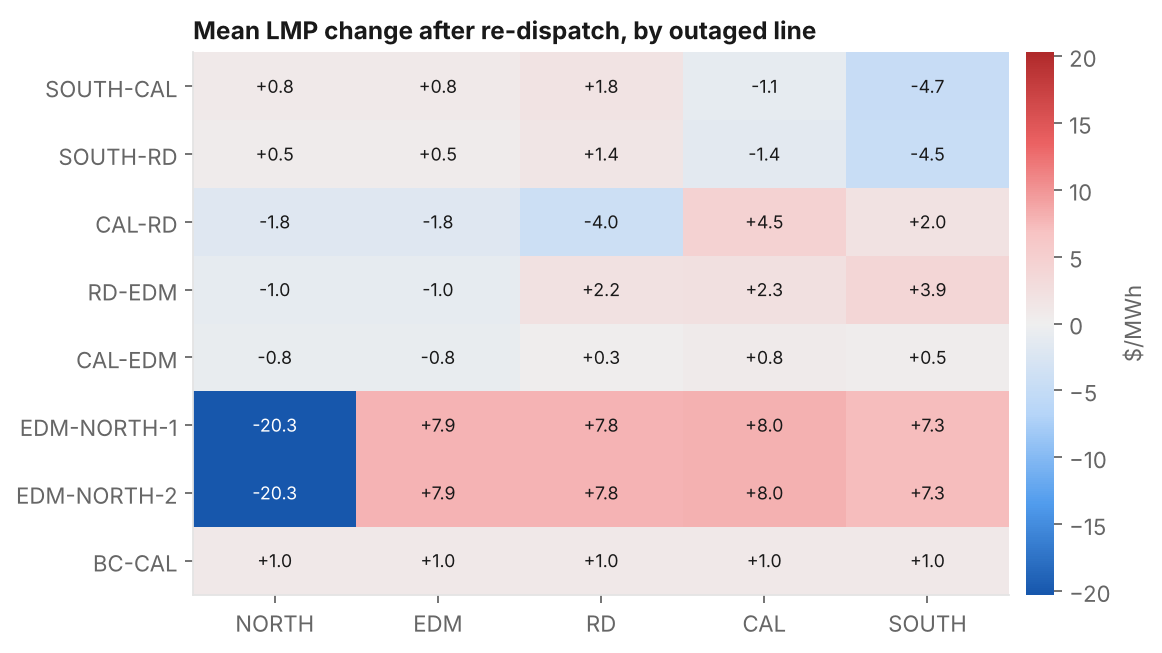

,islands,share_hours_overload,max_post_loading,worst_line,delta_cost_musd_per_year,mean_abs_delta_lmp,unserved_mwh_per_year,rank_security,rank_economic
contingency,,,,,,,,,
EDM-NORTH-1,NaN,0.994,2.000,EDM-NORTH-2,154.046,10.337,485.677,1.0,1.0
EDM-NORTH-2,NaN,0.994,2.000,EDM-NORTH-1,154.046,10.337,485.677,1.0,1.0
CAL-RD,NaN,0.641,1.422,SOUTH-CAL,25.112,3.509,0.000,3.0,5.0
RD-EDM,NaN,0.546,1.753,CAL-EDM,15.345,3.775,0.000,4.0,6.0
SOUTH-CAL,NaN,0.398,2.410,SOUTH-RD,140.488,3.142,1600.130,5.0,3.0
SOUTH-RD,NaN,0.322,1.657,SOUTH-CAL,72.408,1.762,0.000,6.0,4.0
CAL-EDM,NaN,0.223,1.100,SOUTH-CAL,-2.373,0.775,0.000,7.0,8.0
BC-CAL,BC,NaN,NaN,NaN,5.386,0.995,0.000,8.0,7.0


In [8]:
display(Image("reports/figures/n1_security.png", width=720))
display(Image("reports/figures/n1_dlmp_heatmap.png", width=680))
cols = ["islands", "share_hours_overload", "max_post_loading", "worst_line", "delta_cost_musd_per_year",
        "mean_abs_delta_lmp", "unserved_mwh_per_year", "rank_security", "rank_economic"]
pd.read_csv("reports/tables/n1_ranking.csv", index_col=0)[cols].round(3)

### Removing a line can lower cost
In a meshed DC network every line also adds a KVL constraint. Removing one can relieve loop flow on a binding line.
The pipeline re-solves the best such hour independently (scipy, angle formulation) to confirm it is real.

In [9]:
pd.DataFrame({k: v for k, v in summary["checks"].items() if k.startswith("switching")}).T

,line,hour,intact,without_line,saving_per_hour,passed
switching_paradox_CAL-RD,CAL-RD,2025-12-24 12:00:00,231647.478619,230802.135769,845.34285,True
switching_paradox_RD-EDM,RD-EDM,2025-12-24 19:00:00,255340.411125,244725.443545,10614.967581,True
switching_paradox_CAL-EDM,CAL-EDM,2025-06-04 18:00:00,145799.127105,141455.522512,4343.604594,True
